## 문제 1   -   Fashion-MNIST

In [1]:
import os
import random
import numpy as np
import tensorflow as tf

def set_seed(seed_value=42):
    random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)
    np.random.seed(seed_value)
    tf.random.set_seed(seed_value)
set_seed(42)

In [2]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist

# 데이터 로드 및 전처리
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

### DNN

In [3]:
# DNN
dnn_model = models.Sequential(
    [
        layers.Flatten(input_shape=(28, 28)),
        layers.Dense(256, activation="relu"),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

dnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
dnn_model.summary()  # 파라미터 수 확인용

dnn_history = dnn_model.fit(
    x_train, y_train, epochs=10, validation_split=0.2, batch_size=64
)
dnn_loss, dnn_acc = dnn_model.evaluate(x_test, y_test)
print(f"DNN 테스트 정확도: {dnn_acc:.4f}")

C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8210 - loss: 0.5017 - val_accuracy: 0.8608 - val_loss: 0.3907
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8655 - loss: 0.3694 - val_accuracy: 0.8687 - val_loss: 0.3683
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8801 - loss: 0.3278 - val_accuracy: 0.8753 - val_loss: 0.3501
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8876 - loss: 0.3033 - val_accuracy: 0.8785 - val_loss: 0.3447
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8945 - loss: 0.2823 - val_accuracy: 0.8792 - val_loss: 0.3392
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9016 - loss: 0.2640 - val_accuracy: 0.8788 - val_loss: 0.3627
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9059 - loss: 0.2515 - val_accuracy: 0.8803 - val_loss: 0.3610
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9116 - loss: 0.2363 - val_accuracy: 0.

fashion_mnist DNN 모델 예측 결과 및 해석

총 10 에포크 동안 학습이 진행되었으며, 매 에포크마다 훈련 데이터셋의 손실은 꾸준히 감소하고 정확도는 상승하여 마지막 10번째 에포크에서는 훈련 정확도가 약 $91.97$% 에 도달했습니다.

검증 데이터셋 기준 성능(val_accuracy 및 val_loss)을 살펴보면, 학습 초기(약 3~5 에포크)에는 검증 손실이 감소하고 정확도가 약 $88$% 수준까지 향상되었습니다.

그러나 5번째 에포크 이후부터는 훈련 정확도가 계속 높아지는 반면,  
검증 손실이 오히려 미세하게 증가하거나 정체되는 과적합 현상이 관찰됩니다. 검증 정확도는 최고 약 $88.32$%를 기록했습니다.

최종 테스트 데이터 평가 결과, 테스트 정확도는 약 $87.56$%를 기록했습니다.

이는 1차원 구조로 펼쳐진(Flatten) 패션 이미지의 픽셀 정보를 완전연결계층(Dense Layer)만으로 학습했음에도 불구하고,  
의류 품목의 기본적인 특징을 잘 학습하여 비교적 안정적인 분류 성능을 보여주고 있음을 시사합니다.

파라미터 수 계산 과정

dense layer = 입력 노드 수 * 출력 노드 수 + 출력 노드 수(편향, Bias)

dense = 784 * 256 + 256 = 200,704 + 256 = 200,960  
dense_1 = 256 * 128 + 128 = 32,768 + 128 = 32,896  
dense_2 = 128 * 10 + 10 = 1,280 + 10 = 1,290

total = 200,960 + 32,896 + 1,290 = $235,146$ 개

### CNN

In [4]:
# CNN
cnn_model = models.Sequential(
    [
        layers.Reshape((28, 28, 1), input_shape=(28, 28)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        # layers.BatchNormalization(), # 필요 시 주석 해제
        layers.Dense(10, activation="softmax"),
    ]
)

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
cnn_model.summary()  # 파라미터 수 확인용

cnn_history = cnn_model.fit(
    x_train, y_train, epochs=10, validation_split=0.2, batch_size=64
)
cnn_loss, cnn_acc = cnn_model.evaluate(x_test, y_test)
print(f"CNN 테스트 정확도: {cnn_acc:.4f}")

C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\reshaping\reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ reshape (Reshape)                    │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8157 - loss: 0.5090 - val_accuracy: 0.8716 - val_loss: 0.3638
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8770 - loss: 0.3394 - val_accuracy: 0.8823 - val_loss: 0.3257
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8938 - loss: 0.2912 - val_accuracy: 0.8928 - val_loss: 0.2991
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9051 - loss: 0.2577 - val_accuracy: 0.8993 - val_loss: 0.2830
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9148 - loss: 0.2309 - val_accuracy: 0.8988 - val_loss: 0.2814
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9237 - loss: 0.2075 - val_accuracy: 0.8986 - val_loss: 0.2874
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9314 - loss: 0.1866 - val_accuracy: 0.8982 - val_loss: 0.2950
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9383 - loss: 0.1679 - val_accuracy: 0.

fashion_mnist CNN 모델 예측 결과 및 해석 예측 결과 및 해석

총 10 에포크 동안 합성곱 계층(Conv2D)과 풀링 계층(MaxPooling2D)을 통해 이미지의 공간적 특징을 학습한 결과,  
훈련 정확도가 첫 에포크 $81.57$%에서 마지막 10번째 에포크에는 약 $95.33$% 까지 빠르게 상승하고 손실은 $0.1319$까지 감소했습니다.

검증 정확도는 4번째 에포크에서 최고 약 $89.93$%(검증손실 : $0.2830$)를 기록했으며, 5번째 에포크에서 최소 검증 손실($0.2814$)을 달성했습니다.

이후 6~10 에포크에서는 훈련 정확도가 95% 이상으로 계속 상승하는 반면, 검증 손실이 $0.3665$까지 점진적으로 증가하고 검증 정확도가 $89.17$%로 소폭 하락하는 과적합 경향을 보입니다.

최종 테스트 데이터 평가 결과, 테스트 정확도는 약 $89.15$%를 달성하여 높은 분류 성능을 보여주었습니다.

파라미터 수 계산 과정

Conv2D layer = 커널 가로 * 커널 세로 * 입력 채널 수 * 필터(출력 채널) 수 + 필터 수(편향)
MaxPooling2D 및 Flatten은 학습 파라미터 X

conv2D = (3 * 3 * 1) * 32 + 32 = 288 + 32 = 320  
conv2D_1 = (3 * 3 * 32) * 64 + 64 = 18,432 + 64 = 18,496  
dense_3 = 1,600 * 128 + 128 = 204,800 + 128 = 204,928  
dense_4 = 128 * 10 + 10 = 1,280 + 10 = 1,290

total = 320 + 18,496 + 204,928 + 1,290 = $225,034$ 개

### 비교 분석

DNN과 CNN 모델의 결과 비교 및 분석

최종 훈련 정확도 : 91.97% vs 95.33%  
CNN이 훈련 데이터 패턴을 훨씬 정밀하게 학습함

최고 검증 정확도 : 88.32% vs 89.93%  
CNN이 일반화 성능에서도 약 1.61%p 우위

테스트 정확도 : 87.56% vs 89.15%  
CNN이 DNN 대비 약 1.59%p 더 높은 정확도 기록

에포크당 학습 시간 : 약 1초 (1ms/step) vs 약 3초 (4ms/step)  
CNN은 합성곱 연산으로 인해 학습 시간이 약 3배 소요

## 문제 2   -   CIFAR-10

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

# 1. 데이터 로드 및 전처리
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

### DNN

In [17]:
# CIFAR-10 DNN (Residual Dense Block + 배치 정규화)
def build_cifar_dnn():
  inputs = layers.Input(shape=(32, 32, 3))
  x = layers.Flatten()(inputs)
  x = layers.Dense(256, activation="relu")(x)
  x = layers.BatchNormalization()(x)

  # Residual Dense 블록 (차원 일치를 위해 Dense 투영 사용)
  res = layers.Dense(256)(x)
  res = layers.BatchNormalization()(res)
  x = layers.add([x, res])
  x = layers.Activation("relu")(x)

  outputs = layers.Dense(10, activation="softmax")(x)
  return models.Model(inputs, outputs, name="CIFAR_DNN")


dnn_model = build_cifar_dnn()
dnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
dnn_model.summary()

# DNN 모델 학습 및 테스트 평가
print("\n--- CIFAR-10 DNN 학습 시작 ---")
dnn_history = dnn_model.fit(
    x_train, y_train, epochs=15, validation_split=0.2, batch_size=64
)
dnn_loss, dnn_acc = dnn_model.evaluate(x_test, y_test)
print(f"CIFAR-10 DNN 테스트 정확도: {dnn_acc:.4f}\n")

Model: "CIFAR_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_6 (Flatten)           │ (None, 3072)              │               0 │ input_layer_7[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_18 (Dense)              │ (None, 256)               │         786,688 │ flatten_6[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_11        │ (None, 256)               │           1,024 │ dense_18[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_19 (Dense)              │ (None, 256)               │          65,792 │ batch_normalization_11[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_12        │ (None, 256)               │           1,024 │ dense_19[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_4 (Add)                   │ (None, 256)               │               0 │ batch_normalization_11[0]… │
│                               │                           │                 │ batch_normalization_12[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_4 (Activation)     │ (None, 256)               │               0 │ add_4[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_20 (Dense)              │ (None, 10)                │           2,570 │ activation_4[0][0]         │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 857,098 (3.27 MB)

 Trainable params: 856,074 (3.27 MB)

 Non-trainable params: 1,024 (4.00 KB)


--- CIFAR-10 DNN 학습 시작 ---
Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3948 - loss: 1.7154 - val_accuracy: 0.3137 - val_loss: 2.0035
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4584 - loss: 1.5325 - val_accuracy: 0.3414 - val_loss: 1.8958
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4836 - loss: 1.4612 - val_accuracy: 0.4054 - val_loss: 1.6938
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5055 - loss: 1.4003 - val_accuracy: 0.3635 - val_loss: 1.8408
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5220 - loss: 1.3580 - val_accuracy: 0.4202 - val_loss: 1.6454
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5344 - loss: 1.3174 - val_accuracy: 0.4456 - val_loss: 1.6003
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5492 - loss: 1.2799 - val_accuracy: 0.4248 - val_loss: 1.6540
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5595 - los

CIFAR-10 DNN 예측 결과 및 해석

배치 정규화(Batch Normalization)와 잔차 연결(Residual Dense Block)을 적용하여 총 15 에포크 동안 학습을 진행한 결과,  
훈련 정확도는 첫 에포크 $39.48$%에서 마지막 15번째 에포크에는 약 $62.57$%까지 꾸준히 상승하고 손실은 $1.0670$까지 감소했습니다.

그러나 컬러 이미지(32 * 32 * 3, 총 3,072차원)이면서 배경과 사물의 형태가 복잡한 CIFAR-10 데이터셋을 1차원으로 펼쳐(Flatten) 완전연결계층만으로 학습했기 때문에, 단순 흑백 의류 데이터(Fashion-MNIST)에 비해 전반적인 수렴 속도와 정확도가 낮게 형성되었습니다.

검증 정확도는 6번째 에포크에서 최고 약 $44.56$% (검증손실 : $1.6003$)를 기록한 이후 더 이상 개선되지 않고 40~44% 초반대에서 정체되었습니다.  
특히 12번째 에포크에서는 검증 손실이 일시적으로 급등(검증손실 : $8.9207$, 검증정확도 : $17.55$%)하는 배치 정규화 이동 평균의 불안정성도 관찰되었으며, 훈련 정확도($62.57$%)와 검증 정확도($42.25$%) 간 약 $20$%p 이상의 격차가 벌어지며 뚜렷한 과적합 양상을 보였습니다.

최종 테스트 데이터 평가 결과, 테스트 정확도는 약 $42.46$%를 기록했습니다.  
10개 클래스 무작위 추측(10%)보다는 훨씬 높은 수준이나, 공간적 지역 패턴을 포착하지 못하는 DNN 구조의 한계로 인해 복잡한 컬러 객체 분류에서는 성능에 명확한 제약이 있음을 보여줍니다.

파라미터 수 계산 과정

dense_18 = (3,072 * 256) + 256 = 786,432 + 256 = 786,688  
batch_normalization_11 = 256 * 2 => 512개의 학습 파라미터 및 512개의 비학습 파라미터 = 1,024  
dense_19 = (256 * 256) + 256 = 65,536 + 256 = 65,792  
batch_normalization_12 = 256 * 2 * 2 = 1,024  
dense_20 = (256 * 10) + 10 = 2,560 + 10 = 2,570

Trainable params = 786,688 + 512 + 65,792 + 512 + 2,570 = 856,074 개  \
Non-trainable params = 512 + 512 = 1,024 개

Total = 856.074 + 1,024 = $857,098$ 개

### CNN

In [18]:
# 2) CIFAR-10 CNN 모델 (ResNet 스타일 블록 + 배치 정규화)
def resnet_block(tensor, filters):
  y = layers.Conv2D(filters, (3, 3), padding="same", activation="relu")(tensor)
  y = layers.BatchNormalization()(y)
  y = layers.Conv2D(filters, (3, 3), padding="same")(tensor)
  y = layers.BatchNormalization()(y)
  out = layers.add([tensor, y])
  return layers.Activation("relu")(out)


def build_cifar_cnn():
  inputs = layers.Input(shape=(32, 32, 3))
  x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
  x = layers.BatchNormalization()(x)

  # ResNet 블록 적용
  x = resnet_block(x, 32)
  x = layers.MaxPooling2D((2, 2))(x)

  x = resnet_block(x, 32)
  x = layers.MaxPooling2D((2, 2))(x)

  x = layers.Flatten()(x)
  x = layers.Dense(128, activation="relu")(x)
  x = layers.BatchNormalization()(x)
  outputs = layers.Dense(10, activation="softmax")(x)
  return models.Model(inputs, outputs, name="CIFAR_CNN")


cnn_model = build_cifar_cnn()
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
cnn_model.summary()

# CNN 모델 학습 및 테스트 평가
print("\n--- CIFAR-10 CNN 학습 시작 ---")
cnn_history = cnn_model.fit(
    x_train, y_train, epochs=15, validation_split=0.2, batch_size=64
)
cnn_loss, cnn_acc = cnn_model.evaluate(x_test, y_test)
print(f"CIFAR-10 CNN 테스트 정확도: {cnn_acc:.4f}")

Model: "CIFAR_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)             │ (None, 32, 32, 32)        │             896 │ input_layer_8[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_13        │ (None, 32, 32, 32)        │             128 │ conv2d_7[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_9 (Conv2D)             │ (None, 32, 32, 32)        │           9,248 │ batch_normalization_13[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_15        │ (None, 32, 32, 32)        │             128 │ conv2d_9[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_5 (Add)                   │ (None, 32, 32, 32)        │               0 │ batch_normalization_13[0]… │
│                               │                           │                 │ batch_normalization_15[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_5 (Activation)     │ (None, 32, 32, 32)        │               0 │ add_5[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_4               │ (None, 16, 16, 32)        │               0 │ activation_5[0][0]         │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_11 (Conv2D)            │ (None, 16, 16, 32)        │           9,248 │ max_pooling2d_4[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_17        │ (None, 16, 16, 32)        │             128 │ conv2d_11[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_6 (Add)                   │ (None, 16, 16, 32)        │               0 │ max_pooling2d_4[0][0],     │
│                               │                           │                 │ batch_normalization_17[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_6 (Activation)     │ (None, 16, 16, 32)        │               0 │ add_6[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_5               │ (None, 8, 8, 32)          │               0 │ activation_6[0][0]         │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_7 (Flatten)           │ (None, 2048)              │               

 Total params: 283,850 (1.08 MB)

 Trainable params: 283,402 (1.08 MB)

 Non-trainable params: 448 (1.75 KB)


--- CIFAR-10 CNN 학습 시작 ---
Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.5712 - loss: 1.2338 - val_accuracy: 0.5404 - val_loss: 1.2773
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.6723 - loss: 0.9442 - val_accuracy: 0.6056 - val_loss: 1.1123
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.7059 - loss: 0.8472 - val_accuracy: 0.6449 - val_loss: 1.0109
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.7304 - loss: 0.7780 - val_accuracy: 0.6458 - val_loss: 1.0432
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.7518 - loss: 0.7193 - val_accuracy: 0.6506 - val_loss: 1.0285
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.7721 - loss: 0.6615 - val_accuracy: 0.6248 - val_loss: 1.1686
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.7848 - loss: 0.6203 - val_accuracy: 0.6314 - val_loss: 1.1626
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accura

CIFAR-10 CNN 모델 예측 결과 및 해석

배치 정규화와 잔차 블록을 적용하여 총 15 에포크 동안 학습을 진행한 결과, 훈련 정확도가 첫 에포크 $57.12$%에서 마지막 15번째 에포크에는 약 $87.23$%까지 크게 향상되었고, 손실은 $0.3706$까지 감소했습니다.

검증 정확도는 학습 초반인 5번째 에포크에서 최고 약 $65.06$% (검증손실 : $1.0285$)를 기록했습니다.  
그러나 그 이후 에포크가 진행될수록 훈련 정확도는 $87$%대까지 가파르게 상승하는 반면,  
검증 손실이 $1.6221$까지 급격히 치솟고 검증 정확도가 $61$% 안팎으로 떨어지는 뚜렷한 과적합 현상이 나타났습니다.

최종 테스트 데이터 평가 결과, 테스트 정확도는 약 $61.13$%를 기록했습니다.

복잡한 컬러 객체와 배경 정보를 포함한 CIFAR-10 데이터셋의 특성상 완전연결계층 기반의 DNN($42.46$%)에 비해 공간적 특징을 보존하는 CNN 구조가 약 $18.67$%p 더 우수한 분류 성능을 입증했습니다.

파라미터 수 계산 과정

conv2d_7 = (3 * 3 * 3) * 32 + 32 = 864 + 32 = 896  
batch_normalization_13 = 32 * 2 => 64개의 학습 파라미터 및 64개의 비학습 파라미터 = 128  
conv2d_9 = (3 * 3 * 32) * 32 + 32 = 9,216 + 32 = 9,248  
batch_normalization_15 = 32 * 2 * 2 = 128  
conv2d_11 = (3 * 3 * 32) * 32 + 32 = 9,248  
batch_normalization_17 = 32 * 2 * 2 = 128  
dense_21 = (2,048 * 128) + 128 = 262,144 + 128 = 262,272  
batch_normalization_17 = 128 * 2 * 2 = 512  
dense_22 = (128 * 10) + 10 = 1,290

Trainable params = 896 + 64 + 9,248 + 64 + 9,248 + 64 + 262,272 + 256 + 1,290 = 283,402 개  
Non-trainable params = 64 + 64 + 64 + 256 = 448 개

Total = 283,402 + 448 = $283,850$ 개

### 비교 분석

최종 훈련 정확도 : 62.57% vs 87.23%  
CNN이 복잡한 컬러 이미지 패턴을 훨씬 강력하게 학습함

최고 검증 정확도 : 44.56% vs 65.06%  
CNN이 일반화 성능에서 약 20.5%p 우위

테스트 정확도 : 42.46% vs 61.13%  
공간 정보 유지 여부에 따른 성능 격차 뚜렷함

에포크당 학습 시간 : 약 2초 (3ms/step) : 약 12 ~ 14초 (20 ~ 21ms/step)  
CNN은 다중 합성곱 및 배치 연산으로 학습 시간이 더 소요됨

## 문제 3   -   Consider the bikeshare count data

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import tensorflow as tf
from tensorflow.keras import layers, models
import shap

# 1. 데이터 로드
df = pd.read_csv('bike.csv')

# 불필요한 인덱스 컬럼('Unnamed: 0') 및 타겟과 직접 연관된 'casual', 'registered' 제거
# ('bikers'가 전체 자전거 대여 수량 타겟입니다)
X = df.drop(['Unnamed: 0', 'bikers', 'casual', 'registered'], axis=1)
y = df['bikers']

# 범주형 변수와 수치형 변수 분리
categorical_cols = ['mnth', 'weathersit']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

# 전처리 파이프라인 (범주형 One-Hot Encoding, 수치형 StandardScaler)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# 데이터 분할 및 전처리 적용
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# 만약 전처리 후 sparse matrix 형태라면 dense array로 변환
if hasattr(X_train_scaled, "toarray"):
    X_train_scaled = X_train_scaled.toarray()
    X_test_scaled = X_test_scaled.toarray()

In [21]:
# DNN, 1D-CNN, RF

# DNN
dnn_reg = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1) # 회귀 문제
])
dnn_reg.compile(optimizer='adam', loss='mse', metrics=['mae'])
dnn_reg.fit(X_train_scaled, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# 1D-CNN 모델 (입력 형태를 3D로 변환: [Samples, Timesteps, Features])
X_train_1d = np.expand_dims(X_train_scaled, axis=2)
X_test_1d = np.expand_dims(X_test_scaled, axis=2)

cnn_reg = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1], 1)),
    layers.Conv1D(32, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])
cnn_reg.compile(optimizer='adam', loss='mse', metrics=['mae'])
cnn_reg.fit(X_train_1d, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# 랜덤 포레스트(RF)
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_scaled, y_train)

# 성능 평가 함수
def evaluate_model(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"[{model_name}] MSE: {mse:.4f}, R^2 : {r2:.4f}")

evaluate_model(y_test, dnn_reg.predict(X_test_scaled).flatten(), "DNN")
evaluate_model(y_test, cnn_reg.predict(X_test_1d).flatten(), "1D-CNN")
evaluate_model(y_test, rf_reg.predict(X_test_scaled), "Random Forest")

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 915us/step
[DNN] MSE: 2438.7288, R^2 : 0.8685
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
[1D-CNN] MSE: 7750.1548, R^2 : 0.5820
[Random Forest] MSE: 1171.9094, R^2 : 0.9368


성능 평가 및 분석

랜덤 포레스트(Random Forest) 가 $R^2 = 0.9368$로 가장 뛰어난 예측 성능을 기록했습니다.  
자전거 대여 데이터에 포함된 다양한 비선형적 상호작용(시간대, 기온, 근무일 여부 등)을 앙상블 구조로 가장 효과적으로 학습했음을 보여줍니다.

DNN 은 $R^2 = 0.8685$으로 준수한 성능을 보였으나, 완전연결계층의 특성상 세부적인 시계열적 연속성이나 변수 간 복잡한 상호작용을 완전히 포착하는 데는 트리 기반 앙상블보다 다소 한계가 있었습니다.

1D-CNN 은 $R^2 = 0.5820$으로 세 모델 중 가장 낮은 성능을 기록했습니다. 자전거 대여 데이터는 순차적인 이미지나 텍스트 시계열 데이터가 아니라 정형 데이터 형태의 탭ular 특성을 지니고 있어, 1D 컨볼루션 필터가 유의미한 지역 패턴을 추출하는 데 적합하지 않았던 것으로 해석됩니다.


--- Random Forest PFI 중요도 상위 변수 ---
hr: 1.3017
workingday: 0.2902
day: 0.0742
hum: 0.0663
season: 0.0610
atemp: 0.0563
temp: 0.0538
weathersit_light rain/snow: 0.0181
weekday: 0.0137
windspeed: 0.0030


C:\Users\PC\AppData\Local\Temp\ipykernel_13416\2708135453.py:21: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_test_scaled, feature_names=all_feature_names)


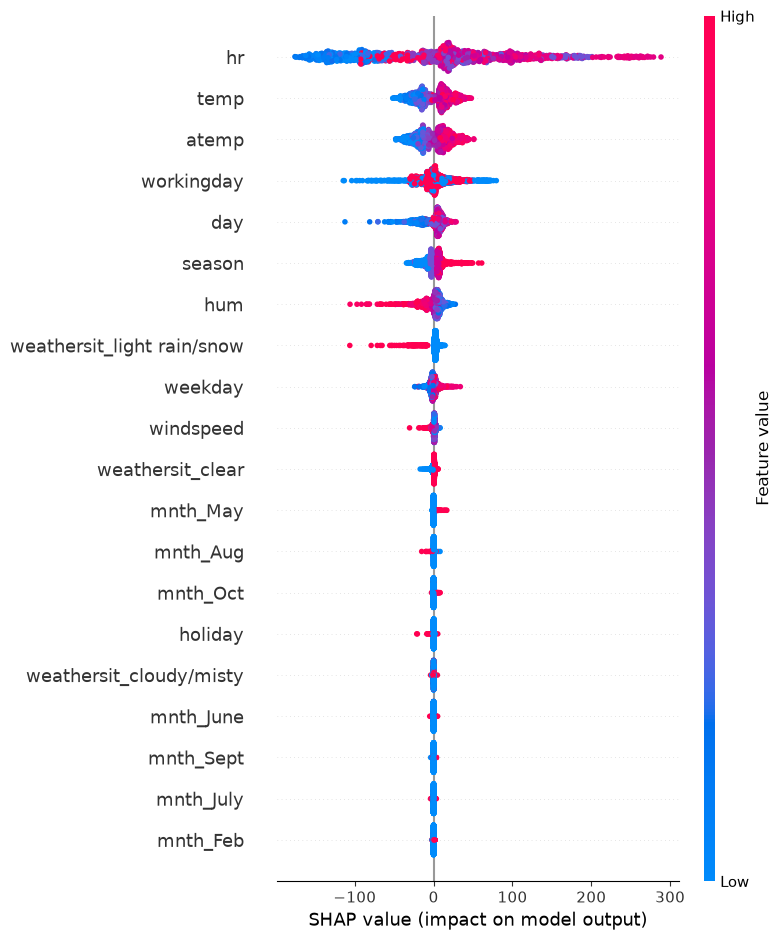

In [22]:
# 변수 중요도 분석 (PFI 및 SHAP)

# 인코딩된 전체 특성(Feature) 이름 추출
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(categorical_cols))
all_feature_names = numerical_cols + encoded_cat_cols

# PFI (Permutation Feature Importance) - Random Forest 기준 예시
result_rf = permutation_importance(rf_reg, X_test_scaled, y_test, n_repeats=10, random_state=42)
sorted_idx = result_rf.importances_mean.argsort()[::-1]

print("\n--- Random Forest PFI 중요도 상위 변수 ---")
for idx in sorted_idx[:10]:
    print(f"{all_feature_names[idx]}: {result_rf.importances_mean[idx]:.4f}")

# SHAP 값 계산 (Random Forest 예시)
explainer_rf = shap.TreeExplainer(rf_reg)
shap_values_rf = explainer_rio = explainer_rf.shap_values(X_test_scaled)

# SHAP 요약 플롯 시각화
shap.summary_plot(shap_values_rf, X_test_scaled, feature_names=all_feature_names)

Compare and interpret the variable importance obtained from the three models using PFI and SHAP.

PFI(Permutation Feature Importance) 분석  
변수를 무작위로 섞었을 때 성능 저하가 가장 큰 상위 변수는 시간(hr, 중요도 $1.3017$) 이며, 그 뒤로 근무일 여부(workingday, $0.2902$), 일자(day, $0.0742$), 습도(hum, $0.0663$), 계절(season, $0.0610$), 체감 온도(atemp, $0.0563$), 기온(temp, $0.0538$) 순으로 나타났습니다.  
이는 자전거 대여 수량이 하루 중 어느 시간대인지와 평일/주말 여부에 가장 큰 영향을 받으며, 기상 조건(습도, 온도)과 계절적 요인이 그다음으로 중요한 역할을 함을 객관적으로 입증합니다.

SHAP(Shapley Additive exPlanations) 분석  
SHAP 요약 플롯에서도 시간(hr)이 모델의 예측값에 가장 큰 폭의 기여(음수에서 양수까지 넓은 분포)를 하는 핵심 변수로 확인됩니다.  
뒤이어 기온(temp), 체감온도(atemp), 근무일 여부(workingday)가 모델 출력에 지대한 영향을 미치는 것으로 나타났습니다.

SHAP 플롯의 색상을 보면, 기온(temp)이나 체감온도(atemp)의 경우 값이 높을수록(빨간색) 모델의 대여량 예측에 양의 기여를 하여 대여 수요를 높이는 방향으로 작용함을 직관적으로 알 수 있습니다.